In [122]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [123]:
homeVista_properties = pd.read_csv("HousePricePrediction.csv") 

In [124]:
# Display first five rows
homeVista_properties.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [125]:
# Check number of rows and columns
homeVista_properties.shape

(2919, 13)

In [126]:
# Check column names and data types
homeVista_properties.info()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   str    
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   str    
 5   BldgType      2919 non-null   str    
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   str    
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), str(4)
memory usage: 352.3 KB


In [127]:
# Check statistical information
homeVista_properties.describe()

,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2918.000000,2918.000000,1460.000000
mean,1459.000000,57.137718,10168.114080,5.564577,1971.312778,1984.264474,49.582248,1051.777587,180921.195890
std,842.787043,42.517628,7886.996359,1.113131,30.291442,20.894344,169.205611,440.766258,79442.502883
min,0.000000,20.000000,1300.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,34900.000000
25%,729.500000,20.000000,7478.000000,5.000000,1953.500000,1965.000000,0.000000,793.000000,129975.000000
50%,1459.000000,50.000000,9453.000000,5.000000,1973.000000,1993.000000,0.000000,989.500000,163000.000000
75%,2188.500000,70.000000,11570.000000,6.000000,2001.000000,2004.000000,0.000000,1302.000000,214000.000000
max,2918.000000,190.000000,215245.000000,9.000000,2010.000000,2010.000000,1526.000000,6110.000000,755000.000000


In [128]:
# Check missing values
homeVista_properties.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64

Text(0.5, 1.0, 'Lot Area vs House Sale Price')

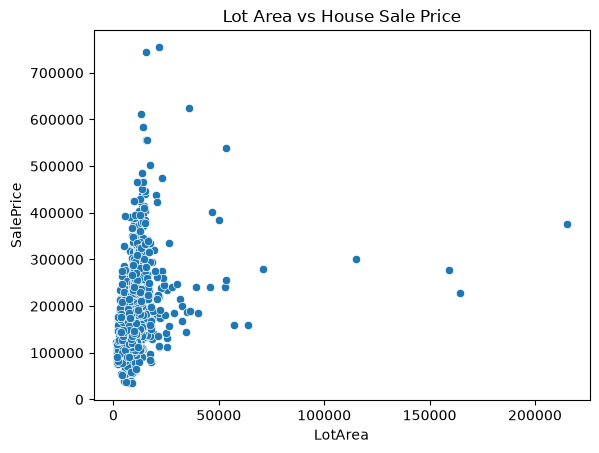

In [129]:
sns.scatterplot(x=homeVista_properties["LotArea"], y=homeVista_properties["SalePrice"])
plt.title("Lot Area vs House Sale Price")

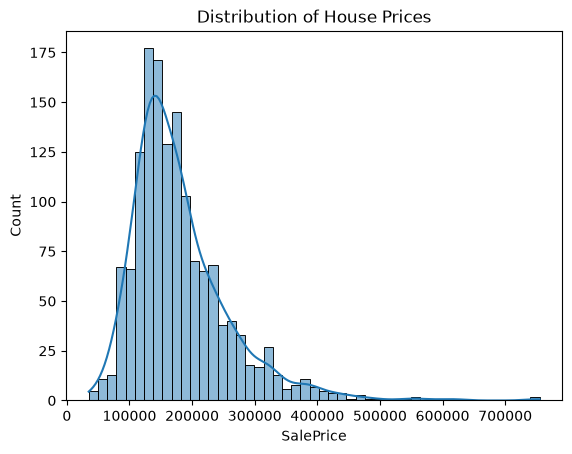

In [130]:
sns.histplot(homeVista_properties["SalePrice"], kde=True)
plt.title("Distribution of House Prices")
plt.show()

In [131]:
# Remove rows where SalePrice is missing
homeVista_properties = homeVista_properties.dropna(subset=["SalePrice"])

X = homeVista_properties.drop(columns=["SalePrice", "Id"], errors="ignore")
Y = homeVista_properties["SalePrice"]

In [132]:
X

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF
0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0
1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0
2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0
3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0
4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0
...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,7917,Inside,1Fam,5,1999,2000,VinylSd,0.0,953.0
1456,20,RL,13175,Inside,1Fam,6,1978,1988,Plywood,163.0,1542.0
1457,70,RL,9042,Inside,1Fam,9,1941,2006,CemntBd,0.0,1152.0
1458,20,RL,9717,Inside,1Fam,6,1950,1996,MetalSd,1029.0,1078.0


In [133]:
Y

0       208500.0
1       181500.0
2       223500.0
3       140000.0
4       250000.0
          ...   
1455    175000.0
1456    210000.0
1457    266500.0
1458    142125.0
1459    147500.0
Name: SalePrice, Length: 1460, dtype: float64

In [134]:
# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category", "str"]
).columns

In [135]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

In [136]:
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),    
    ("regressor" , LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['MSSubClass','MSZoning','LotArea',...,'Exterior1st','BsmtFinSF2', 'TotalBsmtSF']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

In [137]:
y_pred = model.predict(X_test)
print(y_pred)

[172312.08851356 242773.75270177 117226.7861301  161048.48639041
 256329.01562401 157355.18913825 180368.38783766 131891.35964834
 140412.24767711 147766.08166437 126599.60179073 126303.97986966
  97029.52376153 240869.00108413 218393.77061596 175519.55427182
 217640.38365475 176647.66301207 140374.56737567 234527.30656269
 161208.7064667  218181.34727688 197496.6285132  155476.90056561
 225648.58442978 166910.6026629  230063.17236377 113518.86721292
 214992.01778063 204767.34304951 124801.77941195 231383.04996324
 222517.74379715 131602.20037738 252996.13118999 143484.47668439
 171818.41229887 217428.57583379 251811.80860055  84385.17016674
 113891.69793182 217885.47919067 128663.16394148 291962.88348443
 138320.97103087  98949.64405012 125827.4795967  133826.73176309
 321793.450597   144222.64492268 112442.96961162 194786.04736979
 125256.31437985 215366.62995069 153173.17131166 261009.64159186
 181544.34868965 174125.28841169 195902.64788974  90178.09696967
  61913.87748841 216287.4

In [138]:
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
892,154500.0,172312.088514
1105,325000.0,242773.752702
413,115000.0,117226.786130
522,159000.0,161048.486390
1036,315500.0,256329.015624
614,75500.0,157355.189138
218,311500.0,180368.387838
1160,146000.0,131891.359648
649,84500.0,140412.247677
887,135500.0,147766.081664


In [139]:
# R-squared
r2 = r2_score(y_test, y_pred)

# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R-squared:", r2)
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)

R-squared: 0.6137645162980757
Mean Absolute Error: 34538.72453284964
Root Mean Squared Error: 54429.33173192985


In [140]:
n = X_test.shape[0]

# Number of features after preprocessing
p = model.named_steps["preprocessor"].transform(
    X_test
).shape[1]

adjusted_r2 = (1 - (1 - r2) * (n - 1)/(n - p - 1))

print("Adjusted R-squared:", adjusted_r2)

Adjusted R-squared: 0.5575018670974017


In [ ]:
# Import Libraries
# Load Dataset
# Data Exploration
# Data Visualization
# Separate X and Y
# Data Preprocessing – Missing values and encoding
# Train-Test Split
# Train Linear Regression Model
# Make Predictions
# Evaluate Model Performance